In [1]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path

PROJECT_ROOT = Path("/content/drive/MyDrive/H-IDS")

print("Project root:", PROJECT_ROOT)
print("Project exists:", PROJECT_ROOT.exists())

Mounted at /content/drive
Project root: /content/drive/MyDrive/H-IDS
Project exists: True


In [ ]:
!pip install shap -q

In [ ]:
import shap
import xgboost
import numpy as np
import pandas as pd
import joblib

from pathlib import Path

print("SHAP version:", shap.__version__)
print("XGBoost version:", xgboost.__version__)
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)

print("\nSHAP environment ready!")

SHAP version: 0.54.1
XGBoost version: 3.4.1
NumPy version: 2.1.3
Pandas version: 2.2.3

SHAP environment ready!


In [ ]:
PROJECT_ROOT = Path("/content/drive/MyDrive/H-IDS")

BINARY_MODEL_PATH = (
    PROJECT_ROOT / "models/binary/xgboost_binary_bundle.joblib"
)

MULTICLASS_MODEL_PATH = (
    PROJECT_ROOT / "models/multiclass/xgboost_multiclass_bundle.joblib"
)

binary_bundle = joblib.load(BINARY_MODEL_PATH)
multiclass_bundle = joblib.load(MULTICLASS_MODEL_PATH)

print("Binary model loaded:", BINARY_MODEL_PATH.exists())
print("Multiclass model loaded:", MULTICLASS_MODEL_PATH.exists())

/usr/lib/python3.13/pickle.py:1754: UserWarning: [10:24:06] WARNING: /__w/xgboost/xgboost/src/gbm/gbtree.cc:439: Changing updater from `grow_gpu_hist` to `grow_quantile_histmaker`.
  setstate(state)
/usr/lib/python3.13/pickle.py:1754: UserWarning: [10:24:06] WARNING: /__w/xgboost/xgboost/src/context.cc:55: No visible GPU is found, setting device to CPU.
  setstate(state)
/usr/lib/python3.13/pickle.py:1754: UserWarning: [10:24:06] WARNING: /__w/xgboost/xgboost/src/context.cc:218: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  setstate(state)


Binary model loaded: True
Multiclass model loaded: True


/usr/lib/python3.13/pickle.py:1754: UserWarning: [10:24:07] WARNING: /__w/xgboost/xgboost/src/gbm/gbtree.cc:439: Changing updater from `grow_gpu_hist` to `grow_quantile_histmaker`.
  setstate(state)
/usr/lib/python3.13/pickle.py:1754: UserWarning: [10:24:07] WARNING: /__w/xgboost/xgboost/src/context.cc:55: No visible GPU is found, setting device to CPU.
  setstate(state)
/usr/lib/python3.13/pickle.py:1754: UserWarning: [10:24:07] WARNING: /__w/xgboost/xgboost/src/context.cc:218: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  setstate(state)


In [ ]:
def inspect_bundle(bundle, name):
    print(f"\n{'='*50}")
    print(name)
    print(f"{'='*50}")

    if isinstance(bundle, dict):
        for key, value in bundle.items():
            print(f"{key}: {type(value).__name__}")
    else:
        for key, value in vars(bundle).items():
            print(f"{key}: {type(value).__name__}")


inspect_bundle(binary_bundle, "BINARY MODEL")
inspect_bundle(multiclass_bundle, "MULTICLASS MODEL")


BINARY MODEL
model: XGBClassifier
imputer: SimpleImputer
feature_columns: list
label_mapping: dict
decision_threshold: float
best_iteration: int
validation_metrics: dict
created_utc: str
xgboost_version: str

MULTICLASS MODEL
model: XGBClassifier
imputer: SimpleImputer
feature_columns: list
class_names: list
class_to_id: dict
id_to_class: dict
best_iteration: int
num_classes: int
model_type: str


In [ ]:
# Extract existing estimators and preprocessors

binary_model = binary_bundle["model"]
binary_imputer = binary_bundle["imputer"]
binary_features = binary_bundle["feature_columns"]

multiclass_model = multiclass_bundle["model"]
multiclass_imputer = multiclass_bundle["imputer"]
multiclass_features = multiclass_bundle["feature_columns"]

# Inspect binary model
print("BINARY MODEL")
print("Estimator:", type(binary_model).__name__)
print("Imputer:", type(binary_imputer).__name__)
print("Number of features:", len(binary_features))
print("Classes:", binary_model.classes_)
print("Decision threshold:", binary_bundle["decision_threshold"])

# Inspect multiclass model
print("\nMULTICLASS MODEL")
print("Estimator:", type(multiclass_model).__name__)
print("Imputer:", type(multiclass_imputer).__name__)
print("Number of features:", len(multiclass_features))
print("Number of classes:", multiclass_bundle["num_classes"])
print("Class names:", multiclass_bundle["class_names"])

# Verify feature consistency
assert binary_features == multiclass_features
assert len(binary_features) == 78

print("\nSUCCESS: Both models use the same 78 features.")

BINARY MODEL
Estimator: XGBClassifier
Imputer: SimpleImputer
Number of features: 78
Classes: [0 1]
Decision threshold: 0.5

MULTICLASS MODEL
Estimator: XGBClassifier
Imputer: SimpleImputer
Number of features: 78
Number of classes: 15
Class names: ['BENIGN', 'Bot', 'DDoS', 'DoS GoldenEye', 'DoS Hulk', 'DoS Slowhttptest', 'DoS slowloris', 'FTP-Patator', 'Heartbleed', 'Infiltration', 'PortScan', 'SSH-Patator', 'Web Attack Brute Force', 'Web Attack SQL Injection', 'Web Attack XSS']

SUCCESS: Both models use the same 78 features.


In [ ]:
# Inspect processed labels
print("Processed label distribution:")
print(test_df["label"].value_counts())

print("\nOriginal label distribution:")
print(test_df["label_raw"].value_counts().head(20))

Processed label distribution:
label
BENIGN                      451830
DoS Hulk                     38087
PortScan                     32282
DDoS                         25538
DoS GoldenEye                 2058
FTP-Patator                   1318
DoS slowloris                 1106
DoS Slowhttptest              1058
SSH-Patator                    958
Bot                            371
Web Attack Brute Force         301
Web Attack XSS                 135
Infiltration                     9
Web Attack SQL Injection         3
Heartbleed                       2
Name: count, dtype: int64

Original label distribution:
label_raw
BENIGN                        451830
DoS Hulk                       38087
PortScan                       32282
DDoS                           25538
DoS GoldenEye                   2058
FTP-Patator                     1318
DoS slowloris                   1106
DoS Slowhttptest                1058
SSH-Patator                      958
Bot                              371
Web

In [ ]:
# Select 10 BENIGN records
benign_sample = test_df[
    test_df["label"] == "BENIGN"
].head(10)

# Select 10 ATTACK records
attack_sample = test_df[
    test_df["label"] != "BENIGN"
].head(10)

# Combine samples
shap_sample = pd.concat(
    [benign_sample, attack_sample],
    axis=0
).reset_index(drop=True)

# Extract only the 78 model features
X_shap = shap_sample[binary_features].copy()

print("\nSHAP sample shape:", X_shap.shape)

print("\nSelected labels:")
print(shap_sample["label"].value_counts())

assert X_shap.shape == (20, 78)


SHAP sample shape: (20, 78)

Selected labels:
label
BENIGN    10
DDoS      10
Name: count, dtype: int64


In [ ]:
X_shap_imputed = pd.DataFrame(
    binary_imputer.transform(X_shap),
    columns=binary_features,
    index=X_shap.index
)

print("Original shape:", X_shap.shape)
print("Imputed shape:", X_shap_imputed.shape)

print(
    "Missing values after imputation:",
    X_shap_imputed.isnull().sum().sum()
)

Original shape: (20, 78)
Imputed shape: (20, 78)
Missing values after imputation: 0


In [ ]:
print("Total columns:", len(test_df.columns))

print("\nAll column names:")
for i, col in enumerate(test_df.columns):
    print(i, repr(col))

print("\nLast 10 columns:")
print(test_df.columns[-10:].tolist())

Total columns: 82

All column names:
0 'Destination Port'
1 'Flow Duration'
2 'Total Fwd Packets'
3 'Total Backward Packets'
4 'Total Length of Fwd Packets'
5 'Total Length of Bwd Packets'
6 'Fwd Packet Length Max'
7 'Fwd Packet Length Min'
8 'Fwd Packet Length Mean'
9 'Fwd Packet Length Std'
10 'Bwd Packet Length Max'
11 'Bwd Packet Length Min'
12 'Bwd Packet Length Mean'
13 'Bwd Packet Length Std'
14 'Flow Bytes/s'
15 'Flow Packets/s'
16 'Flow IAT Mean'
17 'Flow IAT Std'
18 'Flow IAT Max'
19 'Flow IAT Min'
20 'Fwd IAT Total'
21 'Fwd IAT Mean'
22 'Fwd IAT Std'
23 'Fwd IAT Max'
24 'Fwd IAT Min'
25 'Bwd IAT Total'
26 'Bwd IAT Mean'
27 'Bwd IAT Std'
28 'Bwd IAT Max'
29 'Bwd IAT Min'
30 'Fwd PSH Flags'
31 'Bwd PSH Flags'
32 'Fwd URG Flags'
33 'Bwd URG Flags'
34 'Fwd Header Length'
35 'Bwd Header Length'
36 'Fwd Packets/s'
37 'Bwd Packets/s'
38 'Min Packet Length'
39 'Max Packet Length'
40 'Packet Length Mean'
41 'Packet Length Std'
42 'Packet Length Variance'
43 'FIN Flag Count'
44 'SYN F

In [ ]:
# Search for possible target/label columns
possible_labels = [
    col for col in test_df.columns
    if any(
        word in col.lower()
        for word in ["label", "target", "class"]
    )
]

print("Possible label columns:", possible_labels)

Possible label columns: ['label_raw', 'label']


In [ ]:
# Create SHAP TreeExplainer for existing binary XGBoost model

binary_explainer = shap.TreeExplainer(binary_model)

print("Binary SHAP TreeExplainer created successfully!")

Binary SHAP TreeExplainer created successfully!


In [ ]:
# Calculate SHAP explanations
binary_shap_values = binary_explainer(
    X_shap_imputed
)

print("SHAP calculation completed!")

print("SHAP values shape:",
      binary_shap_values.values.shape)

print("Base values shape:",
      np.asarray(binary_shap_values.base_values).shape)

SHAP calculation completed!
SHAP values shape: (20, 78)
Base values shape: (20,)


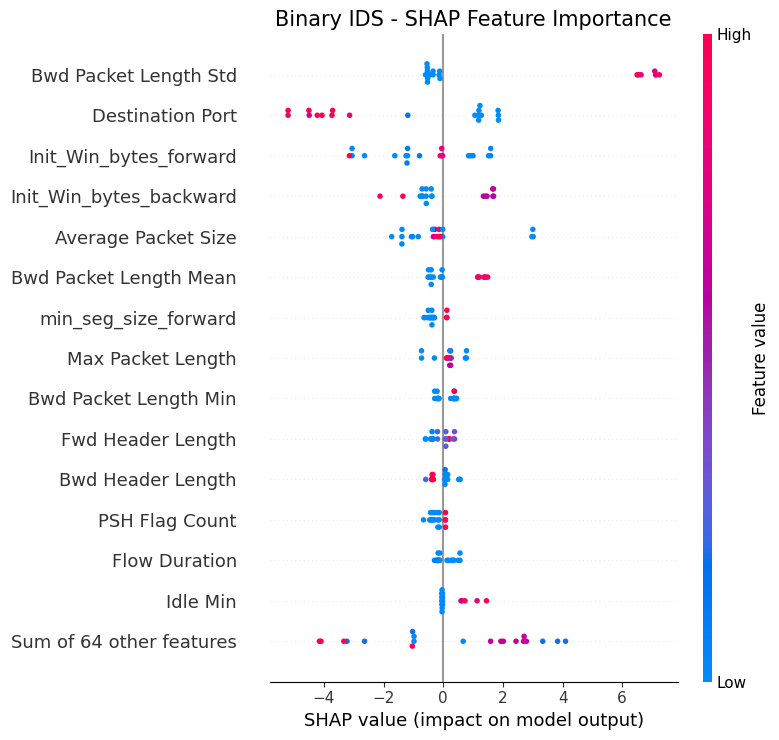

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))

shap.plots.beeswarm(
    binary_shap_values,
    max_display=15,
    show=False
)

plt.title(
    "Binary IDS - SHAP Feature Importance",
    fontsize=15
)

plt.tight_layout()
plt.show()

In [ ]:
print("Actual label:", shap_sample.loc[0, "label"])

print(
    "Predicted class:",
    binary_model.predict(
        X_shap_imputed.iloc[[0]]
    )[0]
)

print(
    "Attack probability:",
    binary_model.predict_proba(
        X_shap_imputed.iloc[[0]]
    )[0][1]
)

Actual label: BENIGN
Predicted class: 0
Attack probability: 3.5739663e-06


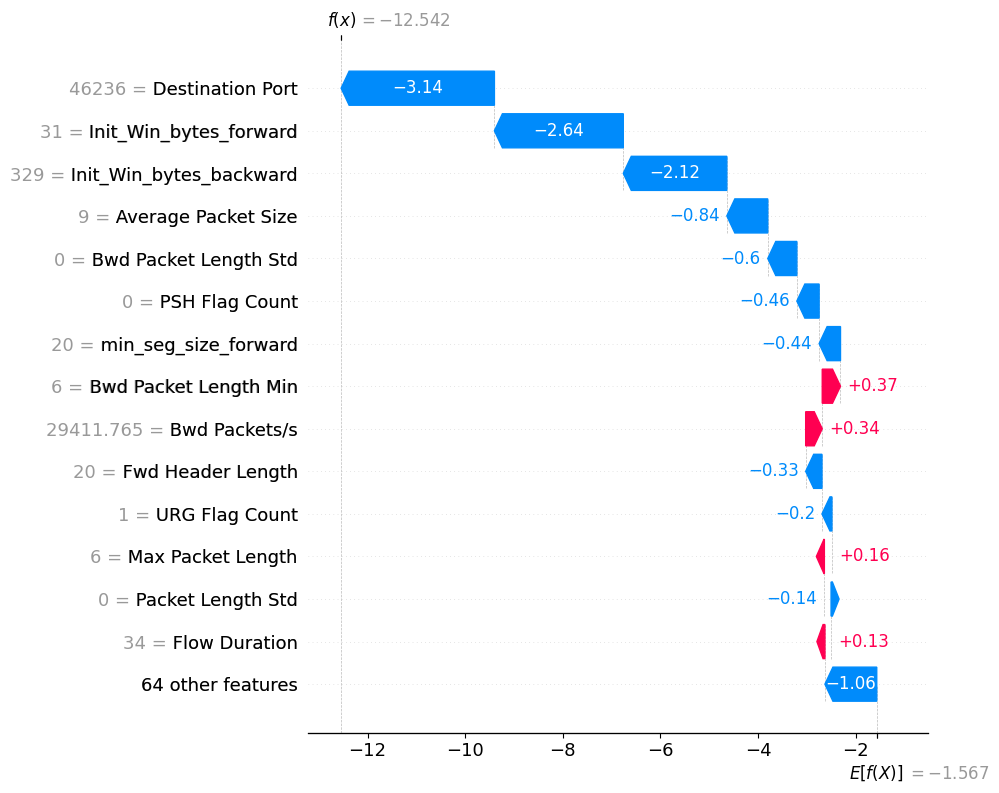

In [ ]:
shap.plots.waterfall(
    binary_shap_values[0],
    max_display=15
)

In [ ]:
attack_index = 10

print(
    "Actual label:",
    shap_sample.loc[attack_index, "label"]
)

print(
    "Predicted class:",
    binary_model.predict(
        X_shap_imputed.iloc[[attack_index]]
    )[0]
)

print(
    "Attack probability:",
    binary_model.predict_proba(
        X_shap_imputed.iloc[[attack_index]]
    )[0][1]
)

Actual label: DDoS
Predicted class: 1
Attack probability: 0.9999956


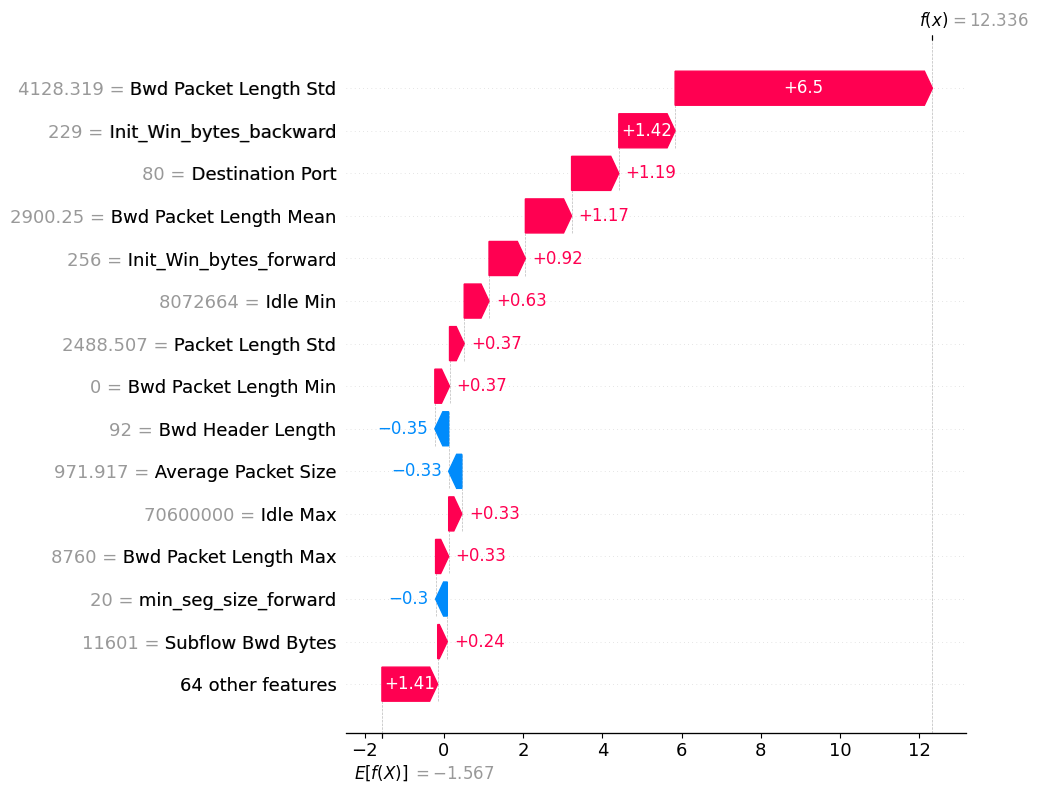

In [ ]:
shap.plots.waterfall(
    binary_shap_values[attack_index],
    max_display=15
)

In [ ]:
# Compare SHAP reconstructed raw model output
# with XGBoost raw prediction output

shap_reconstructed = (
    np.asarray(binary_shap_values.base_values)
    + binary_shap_values.values.sum(axis=1)
)

raw_predictions = binary_model.predict(
    X_shap_imputed,
    output_margin=True
)

print(
    "Maximum SHAP additivity difference:",
    np.max(np.abs(shap_reconstructed - raw_predictions))
)

Maximum SHAP additivity difference: 4.7683716e-06


In [ ]:
# Create SHAP TreeExplainer for existing multiclass model

multiclass_explainer = shap.TreeExplainer(
    multiclass_model
)

print("Multiclass SHAP explainer created successfully!")

Multiclass SHAP explainer created successfully!


In [ ]:
X_attack_shap = X_shap_imputed.iloc[10:].copy()

print("Attack sample shape:", X_attack_shap.shape)

Attack sample shape: (10, 78)


In [ ]:
multiclass_shap_values = multiclass_explainer(
    X_attack_shap
)

print("Multiclass SHAP calculation completed!")

print("SHAP values shape:",
      multiclass_shap_values.values.shape)

print("Base values shape:",
      np.asarray(multiclass_shap_values.base_values).shape)

print("Number of model classes:",
      len(multiclass_bundle["class_names"]))

Multiclass SHAP calculation completed!
SHAP values shape: (10, 78, 15)
Base values shape: (10, 15)
Number of model classes: 15


In [ ]:
multiclass_predictions = multiclass_model.predict(
    X_attack_shap
)

print("Multiclass predictions:")

for i, prediction in enumerate(multiclass_predictions):
    predicted_name = multiclass_bundle["id_to_class"][
        int(prediction)
    ]

    print(
        f"Record {i}: "
        f"Predicted class = {predicted_name}"
    )

Multiclass predictions:
Record 0: Predicted class = DDoS
Record 1: Predicted class = DDoS
Record 2: Predicted class = DDoS
Record 3: Predicted class = DDoS
Record 4: Predicted class = DDoS
Record 5: Predicted class = DDoS
Record 6: Predicted class = DDoS
Record 7: Predicted class = DDoS
Record 8: Predicted class = DDoS
Record 9: Predicted class = DDoS


In [ ]:
ddos_class_id = multiclass_bundle["class_to_id"]["DDoS"]

print("DDoS class ID:", ddos_class_id)

DDoS class ID: 2


In [ ]:
ddos_shap = multiclass_shap_values[
    :, :, ddos_class_id
]

print("DDoS SHAP shape:", ddos_shap.values.shape)
print("DDoS base values:", ddos_shap.base_values.shape)

DDoS SHAP shape: (10, 78)
DDoS base values: (10,)


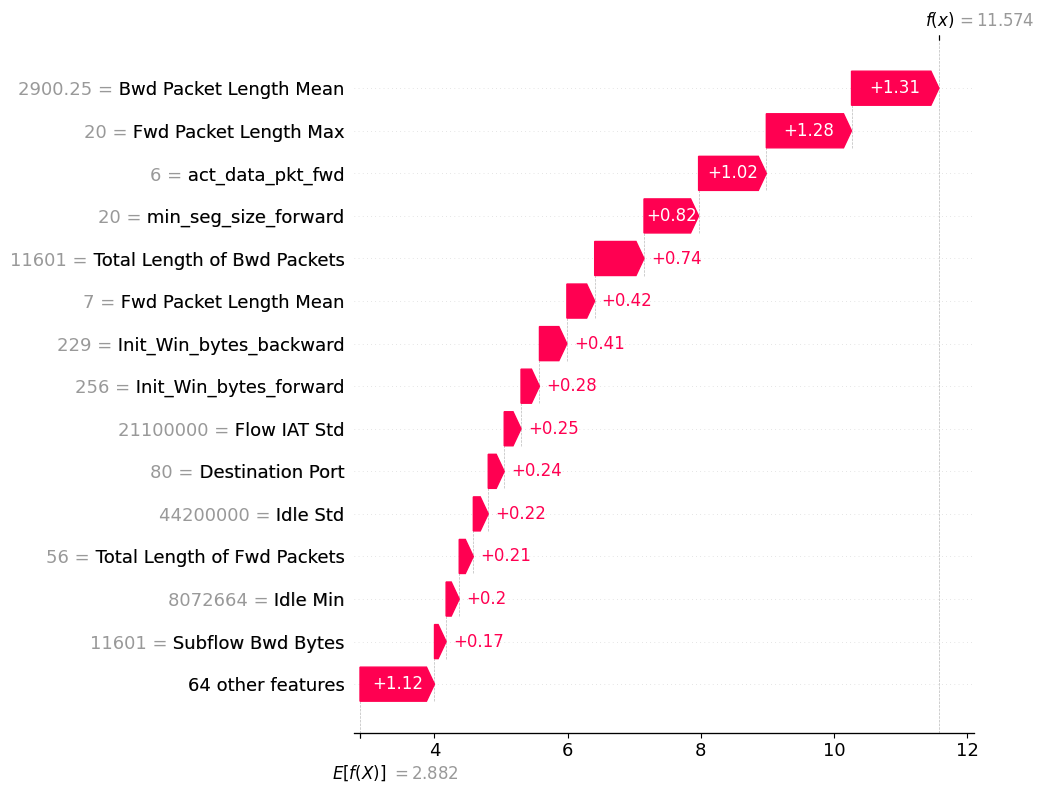

In [ ]:
shap.plots.waterfall(
    ddos_shap[0],
    max_display=15
)

In [ ]:
ddos_importance = np.abs(
    ddos_shap.values
).mean(axis=0)

ddos_importance_df = pd.DataFrame({
    "Feature": multiclass_features,
    "Mean_Absolute_SHAP": ddos_importance
})

ddos_importance_df = ddos_importance_df.sort_values(
    by="Mean_Absolute_SHAP",
    ascending=False
)

print(ddos_importance_df.head(15))

                        Feature  Mean_Absolute_SHAP
68             act_data_pkt_fwd            1.348026
6         Fwd Packet Length Max            1.228486
12       Bwd Packet Length Mean            0.966699
69         min_seg_size_forward            0.784084
5   Total Length of Bwd Packets            0.535816
67      Init_Win_bytes_backward            0.428165
3        Total Backward Packets            0.426660
17                 Flow IAT Std            0.320663
66       Init_Win_bytes_forward            0.280384
4   Total Length of Fwd Packets            0.275540
0              Destination Port            0.269355
8        Fwd Packet Length Mean            0.261253
47               ACK Flag Count            0.260582
36                Fwd Packets/s            0.237734
18                 Flow IAT Max            0.196213


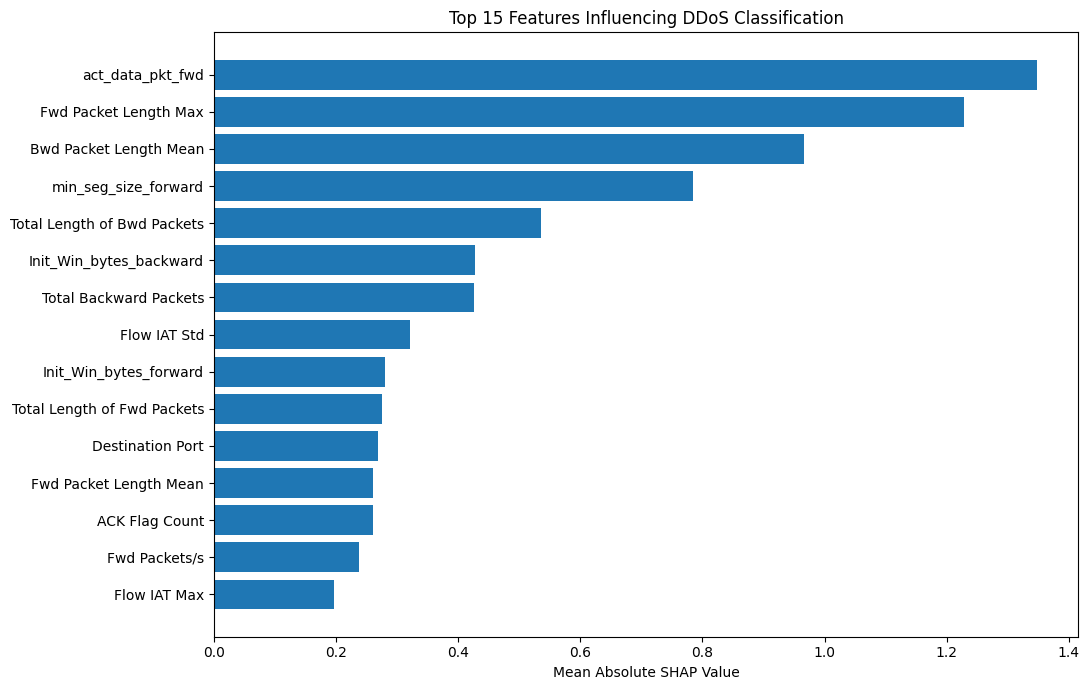

In [ ]:
plt.figure(figsize=(11, 7))

top_features = ddos_importance_df.head(15).sort_values(
    "Mean_Absolute_SHAP"
)

plt.barh(
    top_features["Feature"],
    top_features["Mean_Absolute_SHAP"]
)

plt.xlabel("Mean Absolute SHAP Value")
plt.title("Top 15 Features Influencing DDoS Classification")

plt.tight_layout()
plt.show()

In [ ]:
# Reconstruct raw model outputs for all 15 classes

multiclass_reconstructed = (
    np.asarray(multiclass_shap_values.base_values)
    + multiclass_shap_values.values.sum(axis=1)
)

multiclass_raw_predictions = multiclass_model.predict(
    X_attack_shap,
    output_margin=True
)

print(
    "Maximum multiclass SHAP additivity difference:",
    np.max(
        np.abs(
            multiclass_reconstructed
            - multiclass_raw_predictions
        )
    )
)

Maximum multiclass SHAP additivity difference: 5.722046e-06


In [ ]:
# ============================================
# H-IDS: AUTOMATIC SHAP API INTEGRATION
# ============================================

from pathlib import Path
import shutil

MAIN_PATH = Path(
    "/content/drive/MyDrive/H-IDS/api/main.py"
)

BACKUP_PATH = MAIN_PATH.with_name(
    "main_before_shap_backup.py"
)

# Read existing API code
code = MAIN_PATH.read_text(encoding="utf-8")

# Prevent duplicate modifications
if '@app.post("/explain")' in code:
    print("SHAP endpoint already exists.")
    print("No changes made.")
else:

    # Create backup
    shutil.copy2(MAIN_PATH, BACKUP_PATH)
    print("Backup created:", BACKUP_PATH)

    # ----------------------------------------
    # A. Add SHAP import
    # ----------------------------------------

    import_anchor = "import pandas as pd\n"

    if import_anchor not in code:
        raise RuntimeError("Could not locate pandas import.")

    code = code.replace(
        import_anchor,
        import_anchor + "import shap\n",
        1
    )

    # ----------------------------------------
    # B. Initialize SHAP explainers
    # ----------------------------------------

    model_anchor = (
        "attack_probability_index = "
        "binary_classes.index(attack_class_id)"
    )

    explainer_code = '''

# ============================================
# SHAP EXPLAINABILITY INITIALIZATION
# ============================================

binary_explainer = shap.TreeExplainer(binary_model)

multiclass_explainer = shap.TreeExplainer(multiclass_model)

print("Binary SHAP explainer initialized.")
print("Multiclass SHAP explainer initialized.")

'''

    if model_anchor not in code:
        raise RuntimeError(
            "Could not locate model initialization section."
        )

    code = code.replace(
        model_anchor,
        model_anchor + "\n" + explainer_code,
        1
    )

    # ----------------------------------------
    # C. Add SHAP helper function
    # ----------------------------------------

    helper_code = '''

# ============================================
# SHAP FEATURE EXTRACTION HELPER
# ============================================

def get_top_shap_features(
    shap_values,
    feature_values,
    feature_names,
    top_n=10,
):

    values = np.asarray(shap_values).reshape(-1)
    feature_values = np.asarray(feature_values).reshape(-1)

    if len(values) != len(feature_names):
        raise ValueError(
            "SHAP values and feature names do not match."
        )

    indices = np.argsort(
        np.abs(values)
    )[::-1][:top_n]

    results = []

    for index in indices:

        contribution = float(values[index])

        results.append({
            "feature": feature_names[index],
            "feature_value": float(feature_values[index]),
            "shap_value": contribution,

            "direction": (
                "increases_class_score"
                if contribution > 0
                else "decreases_class_score"
                if contribution < 0
                else "neutral"
            ),
        })

    return results

'''

    endpoint_anchor = '@app.get("/health")'

    if endpoint_anchor not in code:
        raise RuntimeError(
            "Could not locate /health endpoint."
        )

    code = code.replace(
        endpoint_anchor,
        helper_code + "\n" + endpoint_anchor,
        1
    )

    # ----------------------------------------
    # D. Add /explain endpoint
    # ----------------------------------------

    explain_endpoint = '''

# ============================================
# SHAP EXPLANATION ENDPOINT
# ============================================

@app.post("/explain")
def explain_prediction(record: FlowRecord):

    # Validate required features.
    missing = [
        name for name in FEATURES
        if name not in record.features
    ]

    if missing:
        raise HTTPException(
            status_code=422,
            detail={
                "message": "Missing required features.",
                "missing_features": missing,
            },
        )

    try:

        # ------------------------------------
        # 1. Prepare input
        # ------------------------------------

        X = pd.DataFrame(
            [[record.features[name] for name in FEATURES]],
            columns=FEATURES,
        )

        X = X.replace([np.inf, -np.inf], np.nan)

        # ------------------------------------
        # 2. Binary prediction
        # ------------------------------------

        X_binary_array = binary_imputer.transform(X)

        X_binary = pd.DataFrame(
            X_binary_array,
            columns=FEATURES,
        )

        binary_probs = binary_model.predict_proba(
            X_binary_array
        )

        attack_probability = float(
            binary_probs[0, attack_probability_index]
        )

        binary_decision = (
            "ATTACK"
            if attack_probability >= binary_threshold
            else "BENIGN"
        )

        # ------------------------------------
        # 3. Binary SHAP explanation
        # ------------------------------------

        binary_shap_result = binary_explainer(
            X_binary
        )

        binary_shap_values = np.asarray(
            binary_shap_result.values
        )[0]

        binary_base_value = float(
            np.asarray(
                binary_shap_result.base_values
            ).reshape(-1)[0]
        )

        binary_top_features = get_top_shap_features(
            binary_shap_values,
            X_binary.iloc[0].to_numpy(),
            FEATURES,
            top_n=10,
        )

        # ------------------------------------
        # 4. BENIGN prediction response
        # ------------------------------------

        if binary_decision == "BENIGN":

            return {
                "binary_decision": "BENIGN",
                "attack_probability": attack_probability,
                "predicted_label": "BENIGN",
                "multiclass_confidence": None,
                "threshold": binary_threshold,

                "binary_explanation": {
                    "explained_class": "ATTACK",
                    "base_value": binary_base_value,
                    "top_features": binary_top_features,
                },

                "multiclass_explanation": None,
            }

        # ------------------------------------
        # 5. Multiclass prediction
        # ------------------------------------

        X_multi_array = multiclass_imputer.transform(
            X.to_numpy()
        )

        X_multi = pd.DataFrame(
            X_multi_array,
            columns=FEATURES,
        )

        multiclass_probs = multiclass_model.predict_proba(
            X_multi_array
        )[0]

        predicted_id = int(
            np.argmax(multiclass_probs)
        )

        predicted_label = class_names[predicted_id]

        multiclass_confidence = float(
            multiclass_probs[predicted_id]
        )

        # ------------------------------------
        # 6. Multiclass SHAP explanation
        # ------------------------------------

        multiclass_shap_result = multiclass_explainer(
            X_multi
        )

        multiclass_values = np.asarray(
            multiclass_shap_result.values
        )

        predicted_class_shap = multiclass_values[
            0, :, predicted_id
        ]

        multiclass_base_values = np.asarray(
            multiclass_shap_result.base_values
        )

        predicted_class_base = float(
            multiclass_base_values[0, predicted_id]
        )

        multiclass_top_features = get_top_shap_features(
            predicted_class_shap,
            X_multi.iloc[0].to_numpy(),
            FEATURES,
            top_n=10,
        )

        # ------------------------------------
        # 7. Final response
        # ------------------------------------

        return {
            "binary_decision": "ATTACK",
            "attack_probability": attack_probability,
            "predicted_label": predicted_label,
            "multiclass_confidence": multiclass_confidence,
            "threshold": binary_threshold,

            "binary_explanation": {
                "explained_class": "ATTACK",
                "base_value": binary_base_value,
                "top_features": binary_top_features,
            },

            "multiclass_explanation": {
                "explained_class": predicted_label,
                "class_id": predicted_id,
                "base_value": predicted_class_base,
                "top_features": multiclass_top_features,
            },
        }

    except HTTPException:
        raise

    except Exception as exc:
        raise HTTPException(
            status_code=500,
            detail=(
                "Explanation failed: "
                f"{type(exc).__name__}: {exc}"
            ),
        )

'''

    batch_anchor = "class BatchFlowRecord(BaseModel):"

    if batch_anchor not in code:
        raise RuntimeError(
            "Could not locate BatchFlowRecord class."
        )

    code = code.replace(
        batch_anchor,
        explain_endpoint + "\n" + batch_anchor,
        1
    )

    # ----------------------------------------
    # E. Save updated API
    # ----------------------------------------

    MAIN_PATH.write_text(
        code,
        encoding="utf-8"
    )

    print("\nSHAP integration added successfully!")
    print("Updated file:", MAIN_PATH)
    print("Backup file:", BACKUP_PATH)

Backup created: /content/drive/MyDrive/H-IDS/api/main_before_shap_backup.py

SHAP integration added successfully!
Updated file: /content/drive/MyDrive/H-IDS/api/main.py
Backup file: /content/drive/MyDrive/H-IDS/api/main_before_shap_backup.py


In [ ]:
updated_code = MAIN_PATH.read_text(encoding="utf-8")

checks = {
    "SHAP import": "import shap" in updated_code,

    "Binary explainer":
        "binary_explainer = shap.TreeExplainer" in updated_code,

    "Multiclass explainer":
        "multiclass_explainer = shap.TreeExplainer" in updated_code,

    "SHAP helper":
        "def get_top_shap_features" in updated_code,

    "Explain endpoint":
        '@app.post("/explain")' in updated_code,

    "Batch endpoint preserved":
        '@app.post("/predict/batch"' in updated_code,

    "Prediction endpoint preserved":
        '@app.post("/predict"' in updated_code,

    "Health endpoint preserved":
        '@app.get("/health")' in updated_code,

    "Features endpoint preserved":
        '@app.get("/features")' in updated_code,
}

for name, passed in checks.items():
    print(f"{'PASS' if passed else 'FAIL'}: {name}")

assert all(checks.values()), "Some code checks failed."

print("\nAll API verification checks passed!")

PASS: SHAP import
PASS: Binary explainer
PASS: Multiclass explainer
PASS: SHAP helper
PASS: Explain endpoint
PASS: Batch endpoint preserved
PASS: Prediction endpoint preserved
PASS: Health endpoint preserved
PASS: Features endpoint preserved

All API verification checks passed!


In [ ]:
import ast

ast.parse(updated_code)

print("Python syntax validation successful!")

Python syntax validation successful!


In [ ]:
for line in updated_code.splitlines():
    if line.strip().startswith("@app."):
        print(line.strip())

@app.get("/health")
@app.get("/features")
@app.post("/predict", response_model=PredictionResponse)
@app.post("/explain")
@app.post("/predict/batch", response_model=BatchPredictionResponse)


In [ ]:
print("Backup exists:", BACKUP_PATH.exists())
print("Updated file exists:", MAIN_PATH.exists())

Backup exists: True
Updated file exists: True


In [ ]:
import os
import signal

API_PID = 1459  # Previous PID, if it is still running.

try:
    os.kill(API_PID, signal.SIGTERM)
    print("Previous FastAPI process stopped.")
except ProcessLookupError:
    print("Previous process is already stopped.")

Previous process is already stopped.


In [ ]:
%cd /content/drive/MyDrive/H-IDS

!nohup uvicorn api.main:app --host 0.0.0.0 --port 8000 > api.log 2>&1 &

/content/drive/MyDrive/H-IDS


In [ ]:
!sleep 5
!cat api.log

/usr/lib/python3.13/pickle.py:1754: UserWarning: [12:52:14] WARNING: /__w/xgboost/xgboost/src/gbm/gbtree.cc:439: Changing updater from `grow_gpu_hist` to `grow_quantile_histmaker`.
  setstate(state)
/usr/lib/python3.13/pickle.py:1754: UserWarning: [12:52:14] WARNING: /__w/xgboost/xgboost/src/context.cc:55: No visible GPU is found, setting device to CPU.
  setstate(state)
/usr/lib/python3.13/pickle.py:1754: UserWarning: [12:52:14] WARNING: /__w/xgboost/xgboost/src/context.cc:218: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  setstate(state)
/usr/lib/python3.13/pickle.py:1754: UserWarning: [12:52:15] WARNING: /__w/xgboost/xgboost/src/gbm/gbtree.cc:439: Changing updater from `grow_gpu_hist` to `grow_quantile_histmaker`.
  setstate(state)
/usr/lib/python3.13/pickle.py:1754: UserWarning: [12:52:15] WARNING: /__w/xgboost/xgboost/src/context.cc:55: No visible GPU is found, setting device to CPU.
  setstate(state)
/usr/lib/python3.13/pickle.py:1754: U

In [ ]:
import requests

API_URL = " https://levels-atomic-assured-scale.trycloudflare.com"

response = requests.get(
    f"{API_URL}/health",
    timeout=30
)

print("Status:", response.status_code)
print(response.json())

Status: 200
{'status': 'ok', 'binary_model_loaded': True, 'multiclass_model_loaded': True, 'feature_count': 78, 'class_count': 15}


In [ ]:
import requests
import pandas as pd

# Load the model feature names
FEATURES = binary_bundle["feature_columns"]

# Select one genuine DDoS record
ddos_record = test_df[
    test_df["label"] == "DDoS"
].iloc[0]

# Prepare the 78 features
ddos_features = {
    name: float(ddos_record[name])
    for name in FEATURES
}

# Call the SHAP endpoint
response = requests.post(
    f"{API_URL}/explain",
    json={"features": ddos_features},
    timeout=120
)

print("HTTP Status:", response.status_code)

result = response.json()

if response.status_code == 200:

    print("\nPREDICTION")
    print("Binary decision:", result["binary_decision"])
    print("Attack probability:", result["attack_probability"])
    print("Predicted label:", result["predicted_label"])
    print("Multiclass confidence:", result["multiclass_confidence"])

    print("\nBINARY SHAP EXPLANATION")

    binary_df = pd.DataFrame(
        result["binary_explanation"]["top_features"]
    )

    display(binary_df)

    print("\nMULTICLASS SHAP EXPLANATION")

    multiclass_df = pd.DataFrame(
        result["multiclass_explanation"]["top_features"]
    )

    display(multiclass_df)

else:
    print(response.text)

HTTP Status: 404
{"detail":"Not Found"}


In [ ]:
import requests

API_URL = "https://named-beyond-charlotte-walker.trycloudflare.com"

# Check public API routes
response = requests.get(
    f"{API_URL}/openapi.json",
    timeout=30
)

print("HTTP Status:", response.status_code)

if response.status_code == 200:
    api_schema = response.json()

    print("\nAvailable API endpoints:")

    for route in api_schema["paths"]:
        print(route)

    print(
        "\nExplain endpoint registered:",
        "/explain" in api_schema["paths"]
    )
else:
    print(response.text)

HTTP Status: 200

Available API endpoints:
/health
/features
/predict
/predict/batch

Explain endpoint registered: False


In [ ]:
LOCAL_URL = "http://127.0.0.1:8000"

response = requests.get(
    f"{LOCAL_URL}/openapi.json",
    timeout=30
)

print("Local API status:", response.status_code)

if response.status_code == 200:
    local_schema = response.json()

    print("\nLocal endpoints:")

    for route in local_schema["paths"]:
        print(route)

    print(
        "\nLocal explain endpoint registered:",
        "/explain" in local_schema["paths"]
    )
else:
    print(response.text)

Local API status: 200

Local endpoints:
/health
/features
/predict
/explain
/predict/batch

Local explain endpoint registered: True


In [ ]:
!tail -n 60 /content/drive/MyDrive/H-IDS/api.log

/usr/lib/python3.13/pickle.py:1754: UserWarning: [12:52:14] WARNING: /__w/xgboost/xgboost/src/gbm/gbtree.cc:439: Changing updater from `grow_gpu_hist` to `grow_quantile_histmaker`.
  setstate(state)
/usr/lib/python3.13/pickle.py:1754: UserWarning: [12:52:14] WARNING: /__w/xgboost/xgboost/src/context.cc:55: No visible GPU is found, setting device to CPU.
  setstate(state)
/usr/lib/python3.13/pickle.py:1754: UserWarning: [12:52:14] WARNING: /__w/xgboost/xgboost/src/context.cc:218: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  setstate(state)
/usr/lib/python3.13/pickle.py:1754: UserWarning: [12:52:15] WARNING: /__w/xgboost/xgboost/src/gbm/gbtree.cc:439: Changing updater from `grow_gpu_hist` to `grow_quantile_histmaker`.
  setstate(state)
/usr/lib/python3.13/pickle.py:1754: UserWarning: [12:52:15] WARNING: /__w/xgboost/xgboost/src/context.cc:55: No visible GPU is found, setting device to CPU.
  setstate(state)
/usr/lib/python3.13/pickle.py:1754: U

In [ ]:
!ps aux | grep cloudflared

root       51412  0.0  0.0   7344  3624 ?        S    13:37   0:00 /bin/bash -c ps aux | grep cloudflared
root       51414  0.0  0.0   6548  2332 ?        S    13:37   0:00 grep cloudflared


In [ ]:
!pkill -f cloudflared || true

^C


In [ ]:
!pgrep -a cloudflared

In [ ]:
!nohup cloudflared tunnel --url http://localhost:8000 > /content/cloudflared.log 2>&1 &

In [ ]:
import time
import re
from pathlib import Path

time.sleep(8)

log = Path("/content/cloudflared.log").read_text()

print(log)

urls = re.findall(
    r"https://[a-zA-Z0-9-]+\.trycloudflare\.com",
    log
)

if urls:
    API_URL = urls[-1]
    print("\nNew API URL:", API_URL)
else:
    print("\nCloudflare URL not found. Check the log.")

nohup: failed to run command 'cloudflared': No such file or directory


Cloudflare URL not found. Check the log.


In [8]:
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 \
    -O /usr/local/bin/cloudflared

!chmod +x /usr/local/bin/cloudflared

!cloudflared --version

cloudflared version 2026.10.7 (built 2026-10-30-17:05 UTC)


In [ ]:
import requests

response = requests.get(
    "http://127.0.0.1:8000/openapi.json",
    timeout=15
)

print("Local API status:", response.status_code)

routes = response.json()["paths"]

for route in routes:
    print(route)

assert "/explain" in routes
print("\nSHAP endpoint is available locally.")

Local API status: 200
/health
/features
/predict
/explain
/predict/batch

SHAP endpoint is available locally.


In [ ]:
!nohup /usr/local/bin/cloudflared tunnel --url http://localhost:8000 > /content/cloudflared.log 2>&1 &

In [ ]:
import time
import re
from pathlib import Path

time.sleep(10)

log = Path("/content/cloudflared.log").read_text()

print(log)

urls = re.findall(
    r"https://[a-zA-Z0-9-]+\.trycloudflare\.com",
    log
)

if urls:
    API_URL = urls[-1]
    print("\nNEW API URL:", API_URL)
else:
    print("\nTunnel did not start. Share the log output.")

2026-11-02T13:40:42Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-11-02T13:40:42Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-11-02T13:40:45Z INF +--------------------------------------------------------------------------------------------+
2026-11-02T13:40:45Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-11-02T13:40:45Z INF |  https://partially-excellence-liked-objective.trycloud

In [ ]:
import requests

response = requests.get(
    f"{API_URL}/openapi.json",
    timeout=30
)

print("HTTP Status:", response.status_code)

if response.status_code == 200:
    routes = response.json()["paths"]

    print("\nPublic API endpoints:")
    for route in routes:
        print(route)

    assert "/explain" in routes

    print("\nSUCCESS: Public SHAP endpoint is available!")

HTTP Status: 200

Public API endpoints:
/health
/features
/predict
/explain
/predict/batch

SUCCESS: Public SHAP endpoint is available!


In [ ]:
import requests
import pandas as pd

FEATURES = binary_bundle["feature_columns"]

ddos_record = test_df[
    test_df["label"] == "DDoS"
].iloc[0]

ddos_features = {
    name: float(ddos_record[name])
    for name in FEATURES
}

response = requests.post(
    f"{API_URL}/explain",
    json={"features": ddos_features},
    timeout=120
)

print("HTTP Status:", response.status_code)

result = response.json()

if response.status_code == 200:
    print("\nPREDICTION")
    print("Binary decision:", result["binary_decision"])
    print("Attack probability:", result["attack_probability"])
    print("Predicted label:", result["predicted_label"])
    print("Multiclass confidence:", result["multiclass_confidence"])

    print("\nBINARY SHAP EXPLANATION")
    display(pd.DataFrame(
        result["binary_explanation"]["top_features"]
    ))

    print("\nMULTICLASS SHAP EXPLANATION")
    display(pd.DataFrame(
        result["multiclass_explanation"]["top_features"]
    ))
else:
    print(response.text)

HTTP Status: 200

PREDICTION
Binary decision: ATTACK
Attack probability: 0.9999955892562866
Predicted label: DDoS
Multiclass confidence: 0.9999901056289673

BINARY SHAP EXPLANATION


,feature,feature_value,shap_value,direction
0,Bwd Packet Length Std,4.128319e+03,6.498098,increases_class_score
1,Init_Win_bytes_backward,2.290000e+02,1.422261,increases_class_score
2,Destination Port,8.000000e+01,1.192299,increases_class_score
3,Bwd Packet Length Mean,2.900250e+03,1.167188,increases_class_score
4,Init_Win_bytes_forward,2.560000e+02,0.917695,increases_class_score
5,Idle Min,8.072664e+06,0.626796,increases_class_score
6,Packet Length Std,2.488507e+03,0.371028,increases_class_score
7,Bwd Packet Length Min,0.000000e+00,0.370808,increases_class_score
8,Bwd Header Length,9.200000e+01,-0.349004,decreases_class_score
9,Average Packet Size,9.719167e+02,-0.332713,decreases_class_score



MULTICLASS SHAP EXPLANATION


,feature,feature_value,shap_value,direction
0,Bwd Packet Length Mean,2900.25,1.312028,increases_class_score
1,Fwd Packet Length Max,20.00,1.279199,increases_class_score
2,act_data_pkt_fwd,6.00,1.016967,increases_class_score
3,min_seg_size_forward,20.00,0.819635,increases_class_score
4,Total Length of Bwd Packets,11601.00,0.740630,increases_class_score
5,Fwd Packet Length Mean,7.00,0.417361,increases_class_score
6,Init_Win_bytes_backward,229.00,0.411874,increases_class_score
7,Init_Win_bytes_forward,256.00,0.276484,increases_class_score
8,Flow IAT Std,21100000.00,0.252554,increases_class_score
9,Destination Port,80.00,0.239784,increases_class_score


In [ ]:
benign_record = test_df[
    test_df["label"] == "BENIGN"
].iloc[0]

benign_features = {
    name: float(benign_record[name])
    for name in FEATURES
}

response = requests.post(
    f"{API_URL}/explain",
    json={"features": benign_features},
    timeout=120
)

print("HTTP Status:", response.status_code)

result = response.json()

if response.status_code == 200:
    print("\nPREDICTION")
    print("Binary decision:", result["binary_decision"])
    print("Attack probability:", result["attack_probability"])
    print("Predicted label:", result["predicted_label"])

    print("\nBINARY SHAP EXPLANATION")
    display(pd.DataFrame(
        result["binary_explanation"]["top_features"]
    ))

    print("\nMulticlass explanation:",
          result["multiclass_explanation"])
else:
    print(response.text)

HTTP Status: 200

PREDICTION
Binary decision: BENIGN
Attack probability: 3.57396629624418e-06
Predicted label: BENIGN

BINARY SHAP EXPLANATION


,feature,feature_value,shap_value,direction
0,Destination Port,46236.00000,-3.140741,decreases_class_score
1,Init_Win_bytes_forward,31.00000,-2.640896,decreases_class_score
2,Init_Win_bytes_backward,329.00000,-2.121268,decreases_class_score
3,Average Packet Size,9.00000,-0.839018,decreases_class_score
4,Bwd Packet Length Std,0.00000,-0.595958,decreases_class_score
5,PSH Flag Count,0.00000,-0.456403,decreases_class_score
6,min_seg_size_forward,20.00000,-0.437938,decreases_class_score
7,Bwd Packet Length Min,6.00000,0.374120,increases_class_score
8,Bwd Packets/s,29411.76471,0.339275,increases_class_score
9,Fwd Header Length,20.00000,-0.333822,decreases_class_score



Multiclass explanation: None


In [ ]:
import requests
import pandas as pd
import numpy as np

# Use your current Cloudflare URL
API_URL = API_URL.rstrip("/")

# Use the existing 78 model features
FEATURES = list(binary_bundle["feature_columns"])

# Select one genuine DDoS record
ddos_record = test_df[
    test_df["label"] == "DDoS"
].iloc[0]

ddos_features = {
    feature: float(ddos_record[feature])
    for feature in FEATURES
}

# Call original prediction endpoint
predict_response = requests.post(
    f"{API_URL}/predict",
    json={"features": ddos_features},
    timeout=60
)

# Call new SHAP explanation endpoint
explain_response = requests.post(
    f"{API_URL}/explain",
    json={"features": ddos_features},
    timeout=120
)

print("Predict status:", predict_response.status_code)
print("Explain status:", explain_response.status_code)

assert predict_response.status_code == 200
assert explain_response.status_code == 200

predict_result = predict_response.json()
explain_result = explain_response.json()

# Compare prediction fields
comparison = {
    "binary_decision": (
        predict_result["binary_decision"],
        explain_result["binary_decision"]
    ),
    "predicted_label": (
        predict_result["predicted_label"],
        explain_result["predicted_label"]
    ),
    "attack_probability": (
        predict_result["attack_probability"],
        explain_result["attack_probability"]
    ),
    "multiclass_confidence": (
        predict_result["multiclass_confidence"],
        explain_result["multiclass_confidence"]
    ),
    "threshold": (
        predict_result["threshold"],
        explain_result["threshold"]
    )
}

print("\nDDOS PREDICTION COMPARISON")
print("=" * 65)

for field, (original, explainable) in comparison.items():
    print(f"\n{field}")
    print("Original /predict:", original)
    print("/explain:", explainable)

# Verify equality
assert predict_result["binary_decision"] == explain_result["binary_decision"]
assert predict_result["predicted_label"] == explain_result["predicted_label"]

assert np.isclose(
    predict_result["attack_probability"],
    explain_result["attack_probability"],
    atol=1e-7
)

assert np.isclose(
    predict_result["multiclass_confidence"],
    explain_result["multiclass_confidence"],
    atol=1e-7
)

assert np.isclose(
    predict_result["threshold"],
    explain_result["threshold"],
    atol=1e-7
)

print("\nPASS: DDoS predictions are identical.")

Predict status: 200
Explain status: 200

DDOS PREDICTION COMPARISON

binary_decision
Original /predict: ATTACK
/explain: ATTACK

predicted_label
Original /predict: DDoS
/explain: DDoS

attack_probability
Original /predict: 0.9999955892562866
/explain: 0.9999955892562866

multiclass_confidence
Original /predict: 0.9999901056289673
/explain: 0.9999901056289673

threshold
Original /predict: 0.5
/explain: 0.5

PASS: DDoS predictions are identical.


In [ ]:
# Select one genuine BENIGN record
benign_record = test_df[
    test_df["label"] == "BENIGN"
].iloc[0]

benign_features = {
    feature: float(benign_record[feature])
    for feature in FEATURES
}

# Original prediction
predict_response = requests.post(
    f"{API_URL}/predict",
    json={"features": benign_features},
    timeout=60
)

# SHAP-enabled prediction
explain_response = requests.post(
    f"{API_URL}/explain",
    json={"features": benign_features},
    timeout=120
)

print("Predict status:", predict_response.status_code)
print("Explain status:", explain_response.status_code)

assert predict_response.status_code == 200
assert explain_response.status_code == 200

predict_result = predict_response.json()
explain_result = explain_response.json()

print("\nBENIGN PREDICTION COMPARISON")
print("=" * 65)

print("Original decision:", predict_result["binary_decision"])
print("Explain decision:", explain_result["binary_decision"])

print("Original probability:", predict_result["attack_probability"])
print("Explain probability:", explain_result["attack_probability"])

print("Original label:", predict_result["predicted_label"])
print("Explain label:", explain_result["predicted_label"])

# Verify identical predictions
assert predict_result["binary_decision"] == explain_result["binary_decision"]
assert predict_result["predicted_label"] == explain_result["predicted_label"]

assert np.isclose(
    predict_result["attack_probability"],
    explain_result["attack_probability"],
    atol=1e-7
)

assert predict_result["multiclass_confidence"] is None
assert explain_result["multiclass_confidence"] is None
assert explain_result["multiclass_explanation"] is None

print("\nPASS: BENIGN predictions are identical.")

Predict status: 200
Explain status: 200

BENIGN PREDICTION COMPARISON
Original decision: BENIGN
Explain decision: BENIGN
Original probability: 3.57396629624418e-06
Explain probability: 3.57396629624418e-06
Original label: BENIGN
Explain label: BENIGN

PASS: BENIGN predictions are identical.


In [3]:
import subprocess
import os
import time

# Navigate to your project directory
PROJECT_ROOT = "/content/drive/MyDrive/H-IDS"
os.chdir(PROJECT_ROOT)

# Start FastAPI using Uvicorn in the background
log_file = open("/content/fastapi.log", "w")

process = subprocess.Popen(
    [
        "python", "-m", "uvicorn",
        "api.main:app",
        "--host", "0.0.0.0",
        "--port", "8000"
    ],
    stdout=log_file,
    stderr=subprocess.STDOUT,
    start_new_session=True
)

time.sleep(3)

if process.poll() is None:
    print("FastAPI started successfully!")
    print("Process ID:", process.pid)
    print("Backend URL: http://127.0.0.1:8000")
else:
    print("FastAPI failed to start. Check the logs below:")
    print(open("/content/fastapi.log").read())

FastAPI started successfully!
Process ID: 2887
Backend URL: http://127.0.0.1:8000


In [5]:
import requests

response = requests.get("http://127.0.0.1:8000/health")
print("Status:", response.status_code)
print("Response:", response.json())

Status: 200
Response: {'status': 'ok', 'binary_model_loaded': True, 'multiclass_model_loaded': True, 'feature_count': 78, 'class_count': 15}


In [9]:
import subprocess
import time
import re
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/H-IDS")
TUNNEL_LOG = ROOT / "outputs" / "metrics" / "cloudflare_tunnel.log"
TUNNEL_LOG.parent.mkdir(parents=True, exist_ok=True)

tunnel_log_handle = open(TUNNEL_LOG, "w")

tunnel_process = subprocess.Popen(
    [
        "cloudflared",
        "tunnel",
        "--url",
        "http://127.0.0.1:8000",
        "--no-autoupdate",
    ],
    stdout=tunnel_log_handle,
    stderr=subprocess.STDOUT,
)

tunnel_url = None

for _ in range(30):
    time.sleep(2)
    log_text = TUNNEL_LOG.read_text(errors="replace")
    match = re.search(
        r"https://[a-zA-Z0-9-]+\.trycloudflare\.com",
        log_text,
    )
    if match:
        tunnel_url = match.group(0)
        break

if tunnel_url is None:
    print(log_text[-5000:])
    raise RuntimeError("Could not obtain the tunnel URL.")

print("API URL:", tunnel_url)
print("Health URL:", tunnel_url + "/health")

API URL: https://narrative-mighty-period-evaluations.trycloudflare.com
Health URL: https://narrative-mighty-period-evaluations.trycloudflare.com/health
